# TCM Data Audit (Part 1)
CET351 - Machine Learning | Cold-rolling fault diagnosis project

This notebook covers the five audit steps:
1. Load the six CSV files and check integrity
2. Count faults per label and per dataset
3. Check whether fault labels can co-occur (multiclass vs multilabel)
4. Identify products, check overlap between datasets, and check stream order
5. Audit the algebraic relation between torque, roll speed and motor power

Set `DATA_DIR` below to the folder that contains `tcm5_dataset_1.csv` ... `tcm5_dataset_6.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_DIR = "data"
datasets = {i: pd.read_csv(f"{DATA_DIR}/tcm5_dataset_{i}.csv") for i in range(1, 7)}

LABELS = [c for c in datasets[1].columns if c.startswith("Anomaly_")]
PRODUCT_COLS = ["thickness_entry", "thickness_exit", "width", "ys_entry", "ys_exit"]
FEATURES = [c for c in datasets[1].columns if c not in LABELS]
print("n features:", len(FEATURES), "| n labels:", len(LABELS))

c:\Users\HP\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


n features: 51 | n labels: 16


## Step 1: Load files and check integrity

In [2]:
rows = []
for i, df in datasets.items():
    rows.append({
        "dataset": i,
        "rows": len(df),
        "columns": df.shape[1],
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "same_columns_as_ds1": list(df.columns) == list(datasets[1].columns),
        "labels_are_binary": bool(df[LABELS].isin([0, 1]).all().all()),
        "any_fault_rate_%": round(100 * df[LABELS].max(axis=1).mean(), 2),
    })
pd.DataFrame(rows).set_index("dataset")

,rows,columns,missing_values,duplicate_rows,same_columns_as_ds1,labels_are_binary,any_fault_rate_%
dataset,,,,,,,
1,20009,67,0,0,True,True,5.22
2,20001,67,0,0,True,True,5.17
3,20003,67,0,0,True,True,4.90
4,20001,67,0,0,True,True,4.62
5,20005,67,0,0,True,True,5.15
6,20008,67,0,0,True,True,4.77


## Step 2: Fault counts per label and per dataset

In [3]:
counts = pd.DataFrame({i: df[LABELS].sum() for i, df in datasets.items()})
counts.columns = [f"ds{i}" for i in counts.columns]
counts

,ds1,ds2,ds3,ds4,ds5,ds6
Anomaly_Reduction,1045,1035,239,261,243,233
Anomaly_Electric_1,0,0,61,37,39,48
Anomaly_Bearing_1,0,0,13,20,31,36
Anomaly_WorkRoll_1,0,0,56,35,42,56
Anomaly_Electric_2,0,0,70,45,75,57
Anomaly_Bearing_2,0,0,22,43,41,22
Anomaly_WorkRoll_2,0,0,28,56,56,49
Anomaly_Electric_3,0,0,55,57,73,57
Anomaly_Bearing_3,0,0,61,28,50,70
Anomaly_WorkRoll_3,0,0,70,56,63,56


In [4]:
active = (counts > 0).sum()
print("Number of labels with at least one positive coil per dataset:")
print(active.to_string())
print()
print("Rarest active label per dataset (positive count):")
for c in counts.columns:
    nz = counts[c][counts[c] > 0]
    print(c, nz.idxmin(), int(nz.min()))
print()
# fault family totals (Reduction / Electric / Bearing / WorkRoll)
fam = counts.copy()
fam["family"] = [l.split("_")[1] for l in fam.index]
fam.groupby("family").sum()

Number of labels with at least one positive coil per dataset:
ds1     1
ds2     1
ds3    16
ds4    16
ds5    16
ds6    16

Rarest active label per dataset (positive count):
ds1 Anomaly_Reduction 1045
ds2 Anomaly_Reduction 1035
ds3 Anomaly_Bearing_1 13
ds4 Anomaly_Bearing_1 20
ds5 Anomaly_Electric_5 22
ds6 Anomaly_Bearing_5 20



,ds1,ds2,ds3,ds4,ds5,ds6
family,,,,,,
Bearing,0,0,152,185,204,171
Electric,0,0,332,237,316,295
Reduction,1045,1035,239,261,243,233
WorkRoll,0,0,280,259,287,287


## Step 3: Can fault labels co-occur?
If some coils carry two or more positive labels at once, the problem is multilabel and not multiclass.

In [5]:
rows = []
for i, df in datasets.items():
    n = df[LABELS].sum(axis=1)
    vc = n.value_counts().sort_index()
    rows.append({"dataset": i, **{f"{k} labels": int(v) for k, v in vc.items()}})
pd.DataFrame(rows).set_index("dataset").fillna(0).astype(int)

,0 labels,1 labels,2 labels
dataset,,,
1,18964,1045,0
2,18966,1035,0
3,19022,959,22
4,19076,908,17
5,18974,1012,19
6,19054,922,32


In [6]:
# Which label pairs co-occur, pooled over datasets 3-6
pair_counts = {}
for i in range(3, 7):
    df = datasets[i]
    multi = df[df[LABELS].sum(axis=1) >= 2]
    for _, r in multi.iterrows():
        pos = [l.replace("Anomaly_", "") for l in LABELS if r[l] == 1]
        for a in range(len(pos)):
            for b in range(a + 1, len(pos)):
                key = (pos[a], pos[b])
                pair_counts[key] = pair_counts.get(key, 0) + 1
pairs = pd.Series(pair_counts).sort_values(ascending=False)
print("Number of distinct co-occurring pairs:", len(pairs))
pairs.head(15)

Number of distinct co-occurring pairs: 29


Electric_3  Electric_4    7
Electric_1  WorkRoll_3    6
Reduction   Electric_1    5
WorkRoll_3  Electric_5    5
Reduction   Electric_5    4
Bearing_1   WorkRoll_4    4
WorkRoll_2  WorkRoll_3    4
Electric_2  Bearing_2     4
WorkRoll_2  WorkRoll_5    4
Electric_1  WorkRoll_4    3
Reduction   WorkRoll_2    3
Electric_3  WorkRoll_4    3
Reduction   Electric_4    3
WorkRoll_1  WorkRoll_5    3
Electric_4  Bearing_5     3
dtype: int64

In [7]:
# Are co-occurring faults on the same stand, or on different stands?
same, diff = 0, 0
for (a, b), n in pair_counts.items():
    sa = a.split("_")[-1]; sb = b.split("_")[-1]
    if a == "Reduction" or b == "Reduction":
        continue
    if sa == sb: same += n
    else: diff += n
print("pairs on the same stand:", same, "| pairs on different stands:", diff)
print("pairs involving Reduction:", sum(n for (a, b), n in pair_counts.items() if "Reduction" in (a, b)))

pairs on the same stand: 7 | pairs on different stands: 49
pairs involving Reduction: 34


In [8]:
total = sum(int((df[LABELS].sum(axis=1) >= 2).sum()) for df in datasets.values())
faulty = sum(int((df[LABELS].sum(axis=1) >= 1).sum()) for df in datasets.values())
print(f"Coils with 2+ labels: {total} out of {faulty} faulty coils ({100*total/faulty:.2f}%)")
print("Decision: use multilabel (one binary output per label), or at least keep a 'multiple faults' class.")

Coils with 2+ labels: 90 out of 5971 faulty coils (1.51%)
Decision: use multilabel (one binary output per label), or at least keep a 'multiple faults' class.


## Step 4: Products, overlap between datasets, and stream order
A product is identified only from the five product-specification columns (entry/exit thickness, width, entry/exit yield strength). These are inputs set by the order, not process measurements, so a fault does not alter them. The check below confirms that.

In [9]:
def add_product(df):
    df = df.copy()
    df["product"] = (df[PRODUCT_COLS].round(3).astype(str)).agg("|".join, axis=1)
    return df

P = {i: add_product(df) for i, df in datasets.items()}
summary = []
for i, df in P.items():
    vc = df["product"].value_counts()
    summary.append({"dataset": i, "n_products": df["product"].nunique(),
                    "min_coils_per_product": int(vc.min()),
                    "max_coils_per_product": int(vc.max())})
pd.DataFrame(summary).set_index("dataset")

,n_products,min_coils_per_product,max_coils_per_product
dataset,,,
1,4,4641,5227
2,20,821,1111
3,4,4909,5185
4,20,837,1129
5,5,2442,4587
6,25,430,998


In [10]:
# Do products repeat across datasets?
sets = {i: set(df["product"]) for i, df in P.items()}
overlap = pd.DataFrame(index=range(1, 7), columns=range(1, 7), dtype=int)
for a in sets:
    for b in sets:
        overlap.loc[a, b] = len(sets[a] & sets[b])
print("Number of shared products between datasets (diagonal = products in dataset):")
overlap

Number of shared products between datasets (diagonal = products in dataset):


,1,2,3,4,5,6
1,4.0,0.0,0.0,0.0,0.0,0.0
2,0.0,20.0,0.0,0.0,0.0,0.0
3,0.0,0.0,4.0,0.0,0.0,0.0
4,0.0,0.0,0.0,20.0,0.0,20.0
5,0.0,0.0,0.0,0.0,5.0,0.0
6,0.0,0.0,0.0,20.0,0.0,25.0


In [11]:
# Share of rows in each dataset whose product also appears in another dataset
for a in range(1, 7):
    others = set().union(*[sets[b] for b in sets if b != a])
    share = P[a]["product"].isin(others).mean()
    print(f"ds{a}: {100*share:.1f}% of coils belong to a product that also appears in another dataset")

ds1: 0.0% of coils belong to a product that also appears in another dataset
ds2: 0.0% of coils belong to a product that also appears in another dataset
ds3: 0.0% of coils belong to a product that also appears in another dataset
ds4: 100.0% of coils belong to a product that also appears in another dataset
ds5: 0.0% of coils belong to a product that also appears in another dataset
ds6: 88.3% of coils belong to a product that also appears in another dataset


In [12]:
# Is the product column independent of the fault? Fault rate per product (should not be ~0 or ~1 for any product)
for i in [3, 5, 6]:
    df = P[i]
    df["any_fault"] = df[LABELS].max(axis=1)
    r = df.groupby("product")["any_fault"].agg(["mean", "size"]).sort_values("mean")
    print(f"ds{i}: fault rate per product min={r['mean'].min():.3f} max={r['mean'].max():.3f}")

ds3: fault rate per product min=0.043 max=0.061
ds5: fault rate per product min=0.047 max=0.054
ds6: fault rate per product min=0.025 max=0.079


In [13]:
# Stream order: do the same products come in consecutive blocks?
for i, df in P.items():
    run_id = (df["product"] != df["product"].shift()).cumsum()
    run_len = run_id.groupby(run_id).size()
    print(f"ds{i}: {run_id.max()} runs, median run length {int(run_len.median())}, max {int(run_len.max())}")

ds1: 2962 runs, median run length 6, max 37
ds2: 3744 runs, median run length 5, max 23
ds3: 3001 runs, median run length 6, max 32
ds4: 3833 runs, median run length 5, max 21
ds5: 3214 runs, median run length 6, max 32
ds6: 3790 runs, median run length 5, max 19


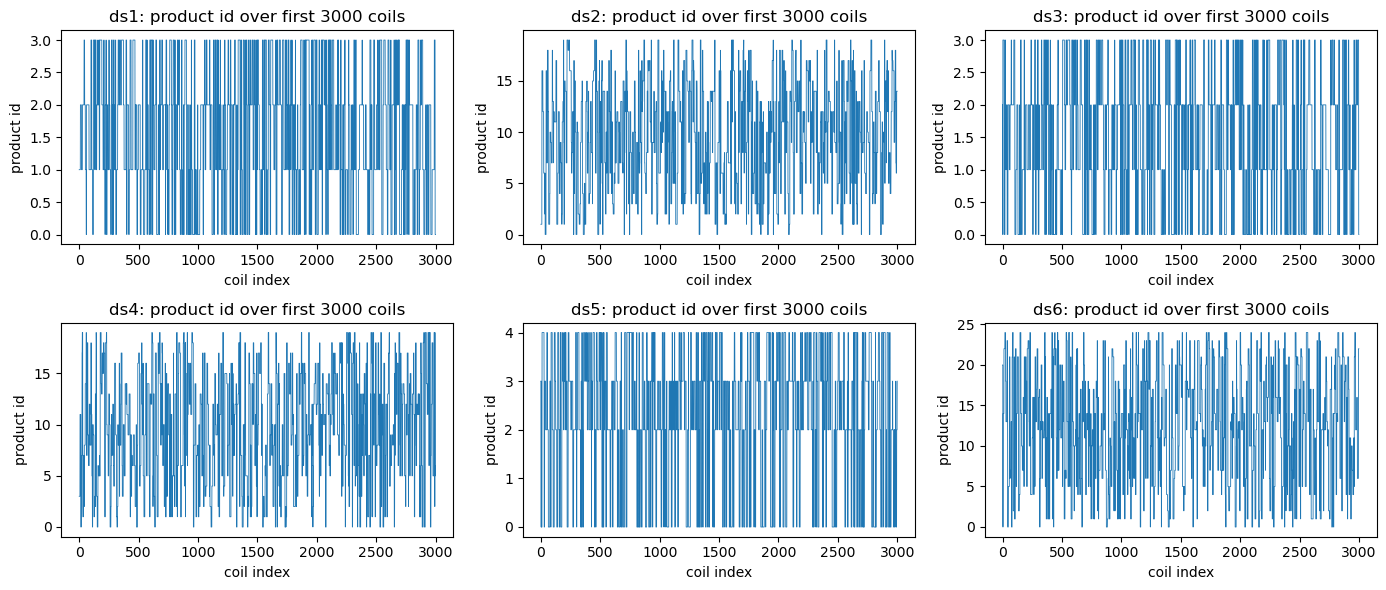

In [14]:
# Visual: product index over stream position
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=False)
for ax, (i, df) in zip(axes.ravel(), P.items()):
    codes = df["product"].astype("category").cat.codes
    ax.plot(codes.values[:3000], lw=0.6)
    ax.set_title(f"ds{i}: product id over first 3000 coils")
    ax.set_xlabel("coil index"); ax.set_ylabel("product id")
plt.tight_layout(); plt.show()

In [15]:
# Internal shift in datasets 5-6: look at the product specs and how they vary over the stream
for i in [5, 6]:
    df = datasets[i]
    thirds = np.array_split(np.arange(len(df)), 4)
    print(f"ds{i}: mean of key columns per quarter of the stream")
    print(pd.DataFrame([df.iloc[idx][["thickness_entry", "width", "ys_entry", "force_3", "motor_power_3"]].mean() for idx in thirds],
                       index=[f"Q{k+1}" for k in range(4)]).round(2))
    print()

ds5: mean of key columns per quarter of the stream
    thickness_entry    width  ys_entry     force_3  motor_power_3
Q1             3.18  1127.83    381.88  7609822.88        3053.44
Q2             3.10  1138.13    387.23  7756817.57        3082.74
Q3             3.04  1158.21    395.46  7992098.13        3090.55
Q4             3.05  1160.37    393.73  7928608.63        3848.80

ds6: mean of key columns per quarter of the stream
    thickness_entry    width  ys_entry     force_3  motor_power_3
Q1             3.23  1077.78    336.49  6545483.71        2849.88
Q2             3.20  1082.65    329.79  6516461.15        2840.10
Q3             3.19  1079.04    328.66  6456837.61        2807.86
Q4             3.20  1078.06    327.79  6413724.34        3477.19



In [16]:
# Per-product coil counts in datasets 5 and 6
for i in [5, 6]:
    print(f"ds{i}")
    print(P[i]["product"].value_counts().head(30).to_string())
    print()

ds5
product
4.0|1.69|1233.0|325.0|521.0    4587
2.9|1.0|1047.0|440.0|673.0     4456
2.5|0.73|1060.0|440.0|690.0    4335
3.2|1.19|1160.0|325.0|535.0    4185
2.6|0.9|1293.0|440.0|672.0     2442

ds6
product
3.3|1.18|1137.0|370.0|582.0    998
3.2|1.36|910.0|281.0|459.0     963
3.6|1.38|994.0|325.0|546.0     950
2.7|0.8|1032.0|440.0|672.0     943
2.8|0.83|1258.0|281.0|492.0    939
4.0|1.68|1147.0|370.0|565.0    918
3.1|1.01|1070.0|281.0|485.0    917
2.9|0.98|1012.0|281.0|481.0    901
3.2|1.22|914.0|370.0|575.0     901
3.0|0.92|1192.0|281.0|491.0    882
3.3|1.26|974.0|281.0|470.0     868
3.9|1.45|1223.0|325.0|550.0    867
3.8|1.65|1185.0|281.0|456.0    862
2.6|0.75|1030.0|370.0|602.0    847
3.8|1.57|905.0|396.0|578.0     846
2.9|0.88|1019.0|370.0|597.0    835
3.4|1.18|1271.0|325.0|558.0    828
3.7|1.37|935.0|440.0|652.0     820
2.6|0.75|1192.0|281.0|494.0    794
2.5|0.79|1173.0|325.0|568.0    785
3.7|1.34|1258.0|370.0|580.0    519
2.9|1.01|942.0|281.0|478.0     512
2.6|0.84|1272.0|281.0|485

## Step 5: Torque / roll speed / motor power relation
If motor power is almost exactly a function of torque and roll speed, a model can learn the simulator equation and detect Electric faults without learning anything transferable. This section measures how tight that relation is, and whether Electric faults break it.

In [17]:
rows = []
for s in range(1, 6):
    for i in [1, 3]:
        df = datasets[i]
        x = df[f"torque_{s}"] * df[f"roll_speed_{s}"]
        y = df[f"motor_power_{s}"]
        ratio = y / x
        healthy = df[LABELS].max(axis=1) == 0
        rows.append({"dataset": i, "stand": s,
                     "corr(power, torque*speed)": round(np.corrcoef(x, y)[0, 1], 4),
                     "ratio mean": ratio.mean(),
                     "ratio CV %": round(100 * ratio.std() / ratio.mean(), 2),
                     "ratio CV % (healthy only)": round(100 * ratio[healthy].std() / ratio[healthy].mean(), 2)})
pd.DataFrame(rows)

,dataset,stand,"corr(power, torque*speed)",ratio mean,ratio CV %,ratio CV % (healthy only)
0,1,1,0.9954,0.003829,1.61,1.60
1,3,1,0.9839,0.003842,4.47,1.73
2,1,2,0.9957,0.003904,1.59,1.59
3,3,2,0.9764,0.003914,4.54,1.65
4,1,3,0.9905,0.003731,1.93,1.93
5,3,3,0.9668,0.003740,4.24,2.00
6,1,4,0.9909,0.003620,1.81,1.81
7,3,4,0.9382,0.003630,4.88,1.83
8,1,5,0.9912,0.003621,1.83,1.83
9,3,5,0.9401,0.003629,4.75,1.80


In [18]:
# Does the Electric fault change the power / (torque*speed) ratio?
rows = []
df = datasets[3]
for s in range(1, 6):
    ratio = df[f"motor_power_{s}"] / (df[f"torque_{s}"] * df[f"roll_speed_{s}"])
    lab = df[f"Anomaly_Electric_{s}"] == 1
    others_healthy = df[LABELS].max(axis=1) == 0
    rows.append({"stand": s, "n_electric": int(lab.sum()),
                 "ratio mean (electric)": ratio[lab].mean(),
                 "ratio mean (healthy)": ratio[others_healthy].mean(),
                 "shift in units of healthy std": (ratio[lab].mean() - ratio[others_healthy].mean()) / ratio[others_healthy].std()})
pd.DataFrame(rows).set_index("stand")

,n_electric,ratio mean (electric),ratio mean (healthy),shift in units of healthy std
stand,,,,
1,61,0.006671,0.003833,42.894773
2,70,0.006664,0.003905,42.809962
3,55,0.006384,0.003733,35.583451
4,76,0.006254,0.003620,39.813401
5,70,0.006309,0.003620,41.373990


In [19]:
# Is the ratio explained by simple physical variables? Fit ratio ~ speed and width on healthy coils (ds3)
from numpy.linalg import lstsq
df = datasets[3]
healthy = df[LABELS].max(axis=1) == 0
for s in range(1, 6):
    ratio = (df[f"motor_power_{s}"] / (df[f"torque_{s}"] * df[f"roll_speed_{s}"]))[healthy].values
    X = np.column_stack([np.ones(healthy.sum()), df.loc[healthy, f"roll_speed_{s}"], df.loc[healthy, f"torque_{s}"], df.loc[healthy, "width"]])
    beta, *_ = lstsq(X, ratio, rcond=None)
    pred = X @ beta
    r2 = 1 - ((ratio - pred) ** 2).sum() / ((ratio - ratio.mean()) ** 2).sum()
    print(f"stand {s}: R2 of ratio explained by speed, torque, width = {r2:.3f}")

stand 1: R2 of ratio explained by speed, torque, width = 0.002
stand 2: R2 of ratio explained by speed, torque, width = 0.003
stand 3: R2 of ratio explained by speed, torque, width = 0.010
stand 4: R2 of ratio explained by speed, torque, width = 0.008
stand 5: R2 of ratio explained by speed, torque, width = 0.005


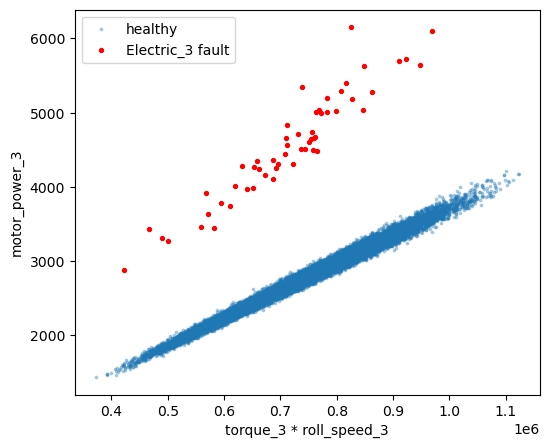

In [20]:
# Scatter plot, stand 3, ds3
df = datasets[3]
x = df["torque_3"] * df["roll_speed_3"]; y = df["motor_power_3"]
healthy = df[LABELS].max(axis=1) == 0
elec = df["Anomaly_Electric_3"] == 1
plt.figure(figsize=(6, 5))
plt.scatter(x[healthy], y[healthy], s=3, alpha=0.3, label="healthy")
plt.scatter(x[elec], y[elec], s=8, c="red", label="Electric_3 fault")
plt.xlabel("torque_3 * roll_speed_3"); plt.ylabel("motor_power_3"); plt.legend(); plt.show()

In [21]:
# Simple physical rule-based baseline: flag a coil if ratio is far from healthy ratio (stand-level Electric detector)
from sklearn.metrics import average_precision_score, f1_score
df = datasets[3]
healthy = df[LABELS].max(axis=1) == 0
rows = []
for s in range(1, 6):
    ratio = df[f"motor_power_{s}"] / (df[f"torque_{s}"] * df[f"roll_speed_{s}"])
    mu, sd = ratio[healthy].mean(), ratio[healthy].std()
    score = ((ratio - mu) / sd).abs()
    y = df[f"Anomaly_Electric_{s}"]
    best_f1 = max(f1_score(y, score > t) for t in np.linspace(0.5, 6, 23))
    rows.append({"stand": s, "PR-AUC": round(average_precision_score(y, score), 3), "best F1": round(best_f1, 3)})
pd.DataFrame(rows).set_index("stand")

,PR-AUC,best F1
stand,,
1,1.0,1.0
2,1.0,1.0
3,1.0,1.0
4,1.0,1.0
5,1.0,1.0


## Summary of findings

- Data integrity: six files, about 20,000 coils each, 67 columns (51 features + 16 labels), no missing values, no duplicate rows, labels are binary.
- Active labels: ds1 and ds2 only have Anomaly_Reduction (about 1,040 positives). ds3-ds6 have all 16 labels, but some are rare (for example Bearing_1 has 13 positives in ds3), so per-label metrics will be noisy.
- Co-occurrence: ds3-ds6 contain coils with 2 labels at once (90 of 5,971 faulty coils, 1.5%). Most co-occurring pairs are on different stands, and Reduction is involved in many of them. Labels are not mutually exclusive, so the task should be multilabel (or multiclass with an extra "multiple faults" class).
- Products: ds1=4, ds2=20, ds3=4, ds4=20, ds5=5, ds6=25 products. ds1, ds2, ds3 and ds5 share no product with any other file. ds4 and ds6 share the same 20 products (ds6 adds 5 new ones, about 12% of its coils). This is the main source-target link found so far and needs to be confirmed against the dataset documentation.
- Stream order: products come in short runs (median 5-6 coils), not in long blocks. A chronological split therefore does not separate products by itself; unseen-product evaluation needs an explicit product-grouped split in addition to the time order.
- Internal shift in ds5/ds6: motor_power_3 jumps in the last quarter of the stream while force stays similar, which matches the "higher production capacity" shift. The exact change point still needs to be located.
- Torque / power: healthy power is almost exactly proportional to torque * roll_speed (ratio CV about 1.6-2.0%, and not explained by speed, torque or width). Electric faults shift this ratio by about 35-43 healthy standard deviations, and a one-line rule on this ratio reaches PR-AUC 1.0 and F1 1.0 for Electric_1..5 in ds3. Electric detection is therefore a simulator-equation shortcut, and any learned model must be compared against this rule-based baseline.
